
[notice] A new release of pip available: 22.2.2 -> 26.0
[notice] To update, run: pip install --upgrade pip


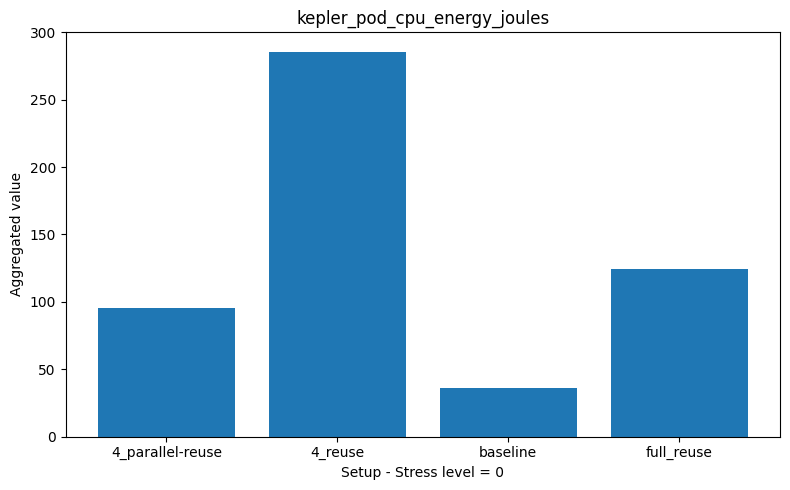

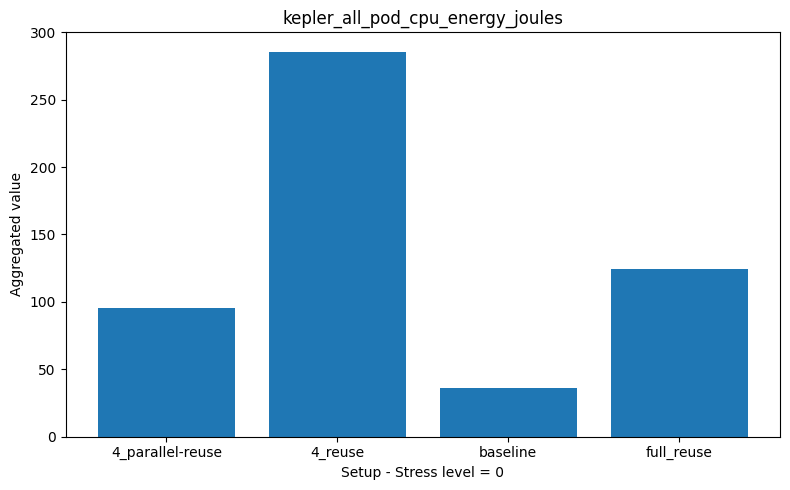

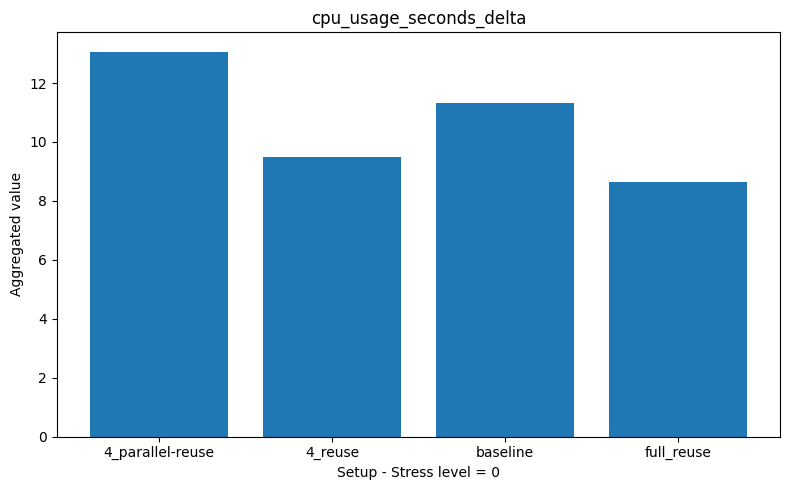

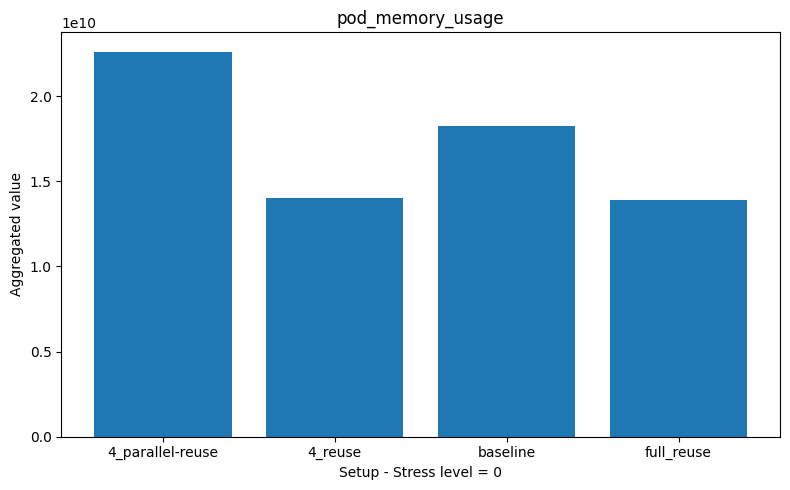

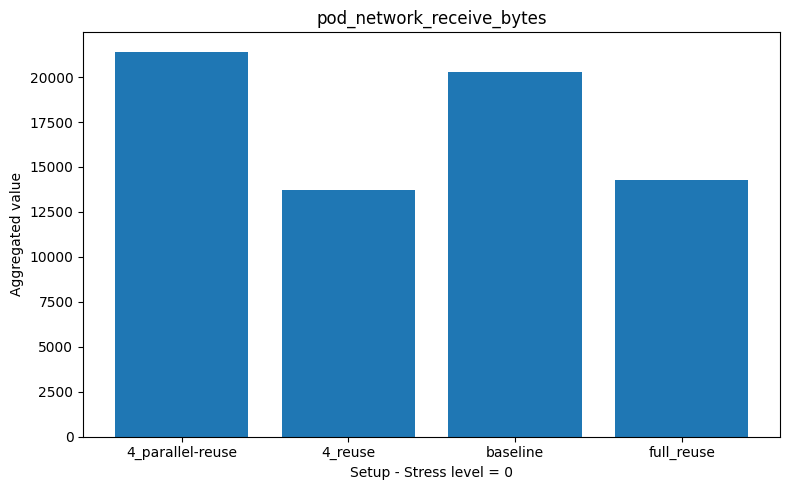

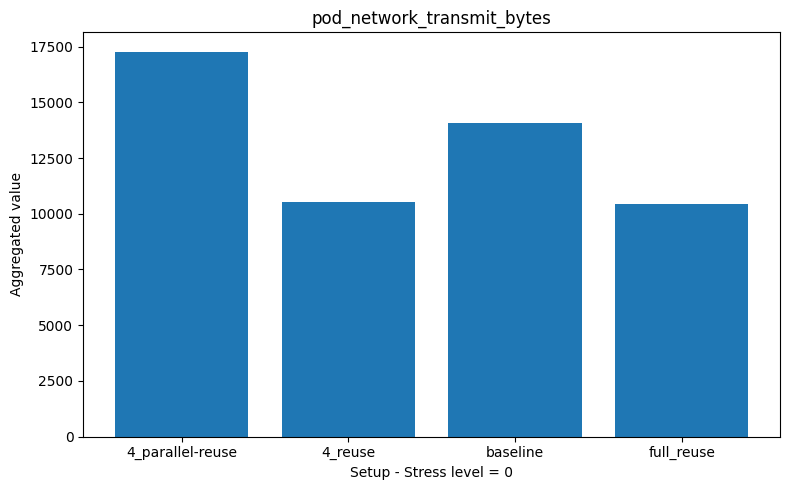

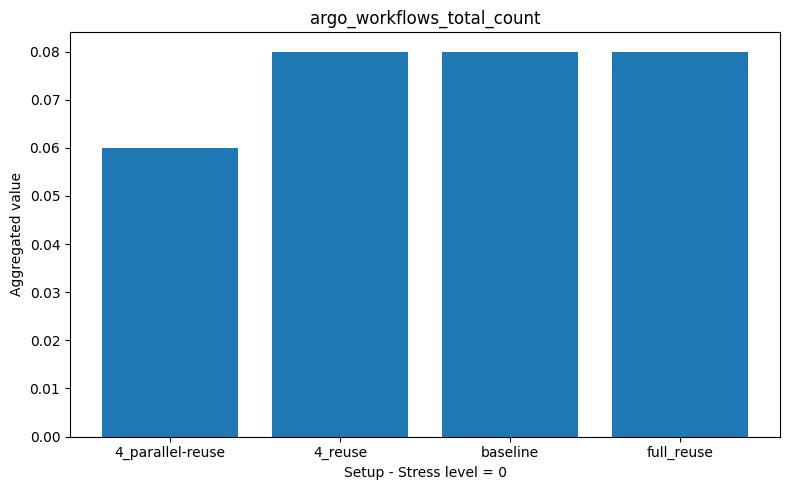

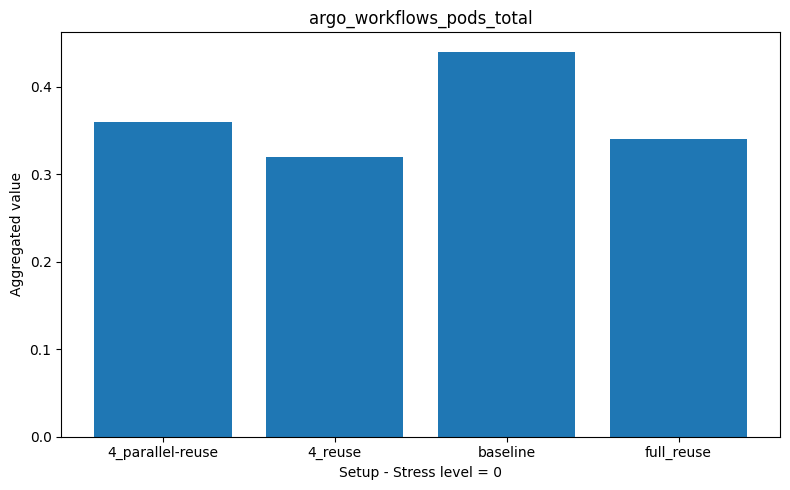

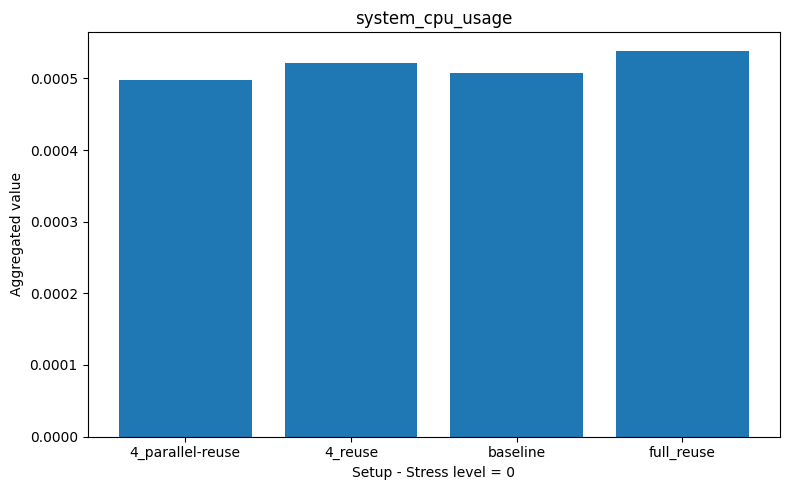

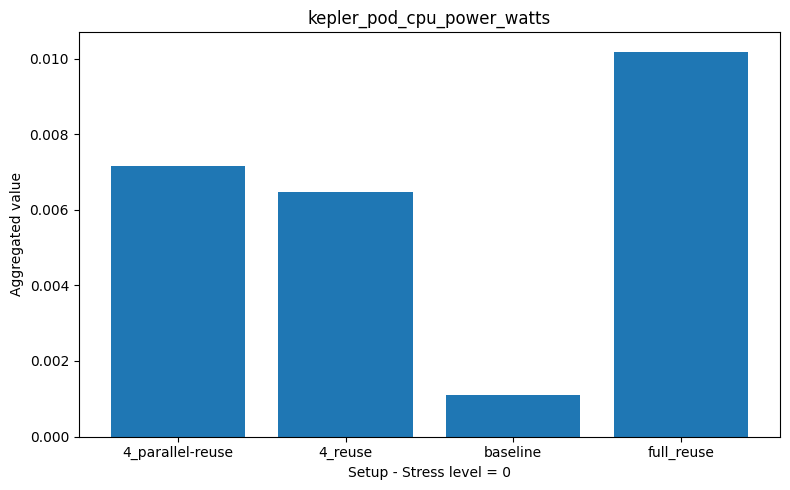

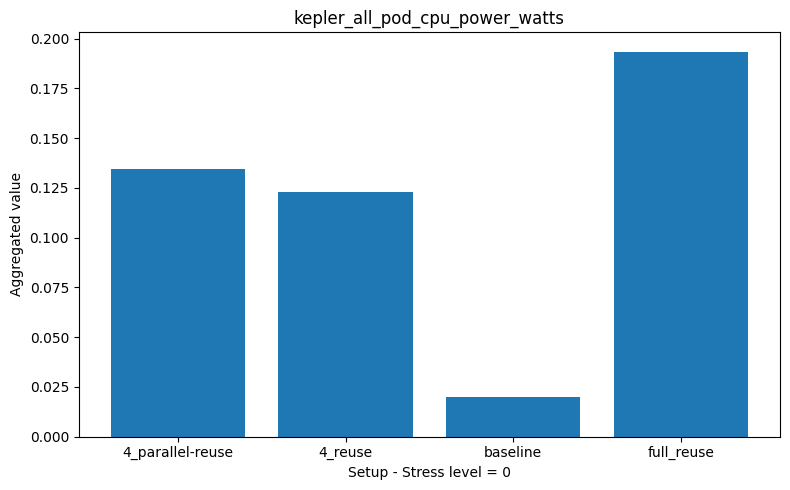

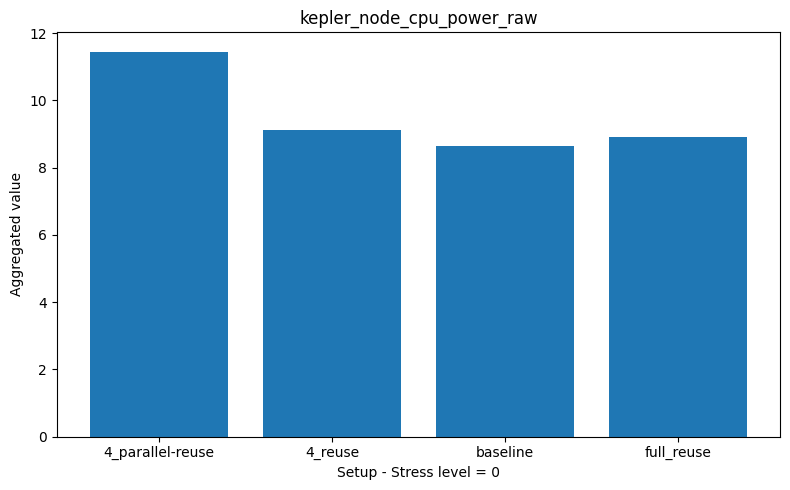

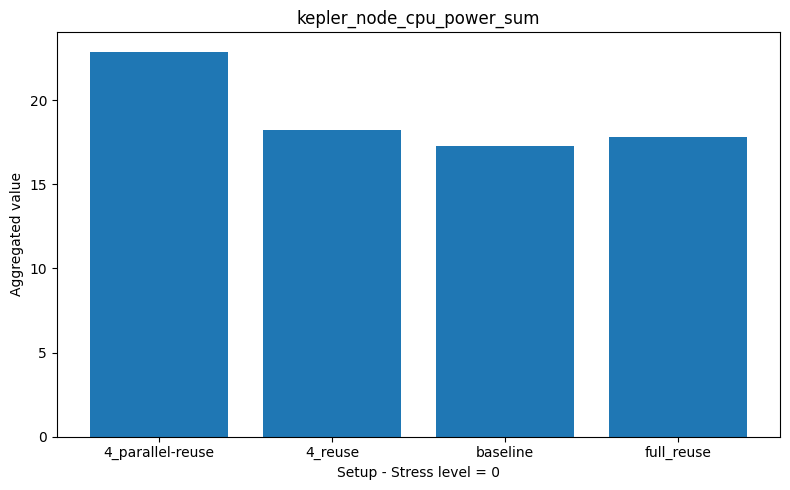

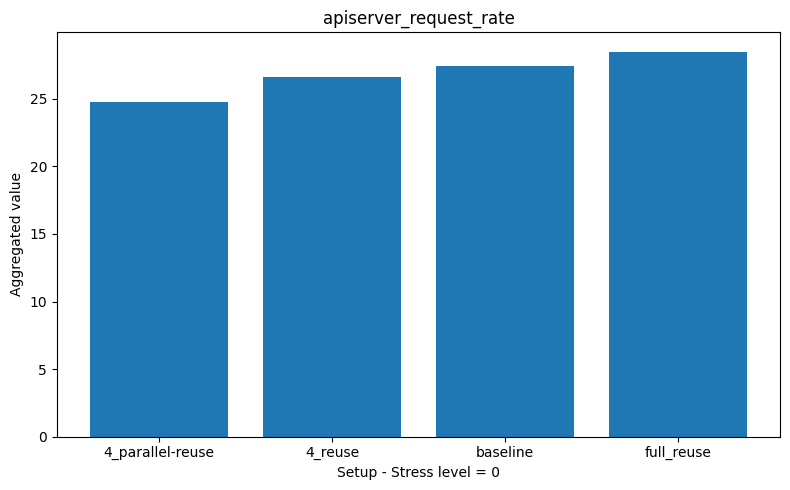

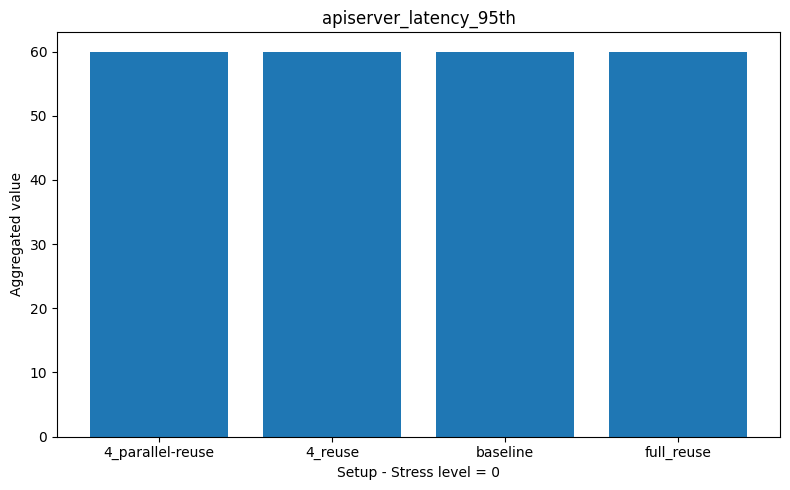

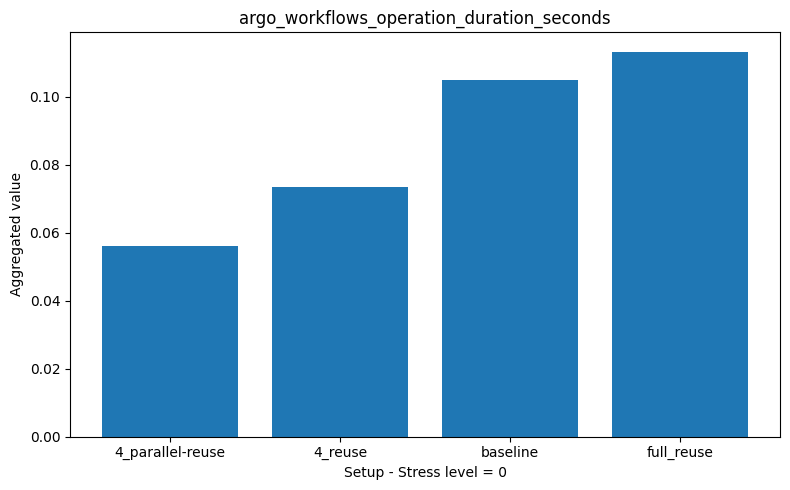

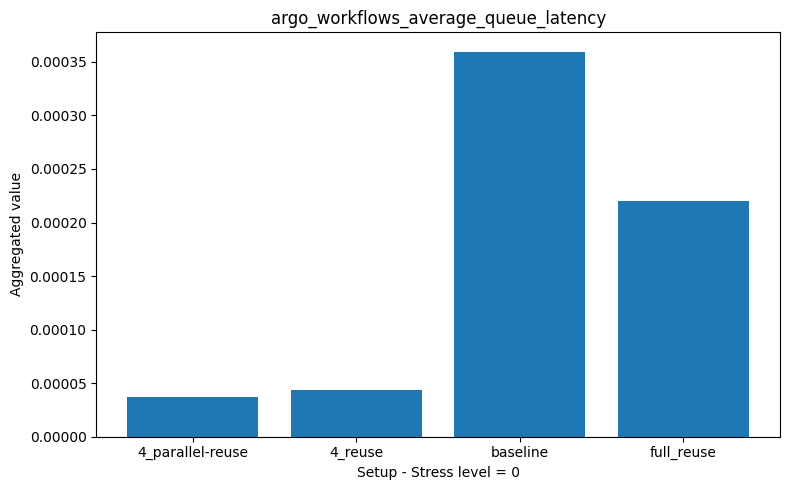

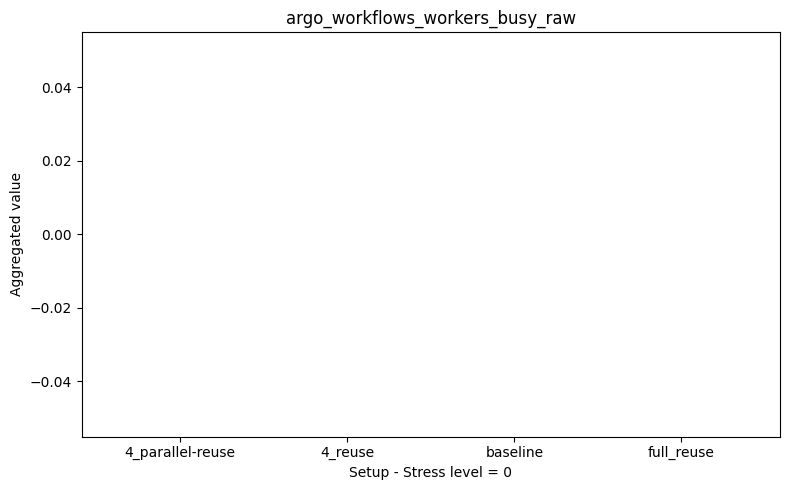

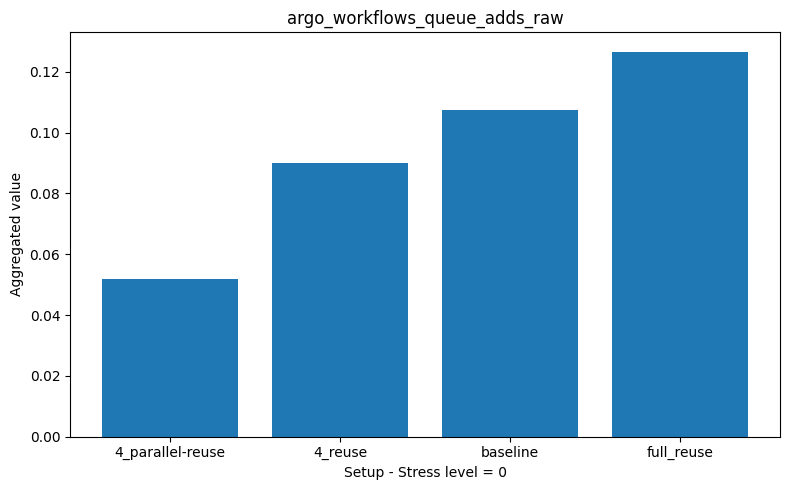

In [4]:
################# IMPACT OF NUMBER OF REUSED STEPS - STRESS=0 #################
#
#
# =========================================================
# Cell 1 – install required libraries (run first)
# =========================================================
!pip install pandas matplotlib numpy


# =========================================================
# Cell 2 – imports and global config
# =========================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)


# =========================================================
# Cell 3 – experiment structure
# =========================================================
SETUPS = {
    "4_parallel-reuse": "./step_reuse_1000_baremetal_2026_02_04_16_31_18_8952049d/data/", # 4_parallel-reuse
    "4_reuse": "./step_reuse_1000_baremetal_2026_02_04_16_37_15_855de02e/data/", # 4-reuse
    "baseline": "./step_reuse_1000_baremetal_2026_02_04_16_41_07_4b4bba30/data/", # baseline
    "full_reuse": "./step_reuse_1000_baremetal_2026_02_04_16_46_47_dc9db2e2/data/",  # full_reuse
} 

SUM_METRICS = [
    "kepler_pod_cpu_energy_joules",
    "kepler_all_pod_cpu_energy_joules",
    "cpu_usage_seconds_delta",
    "pod_memory_usage",
    "pod_network_receive_bytes",
    "pod_network_transmit_bytes",
    "argo_workflows_total_count",
    "argo_workflows_error_count",
    "argo_workflows_pods_total",
]

MEAN_METRICS = [
    "system_cpu_usage",
    "kepler_pod_cpu_power_watts",
    "kepler_all_pod_cpu_power_watts",
    "kepler_node_cpu_power_raw",
    "kepler_node_cpu_power_sum",
    "wall_power",
    "apiserver_request_rate",
    "apiserver_latency_95th",
    "argo_workflows_operation_duration_seconds",
    "argo_workflows_average_queue_latency",
    "argo_workflows_workers_busy_raw",
    "argo_workflows_queue_adds_raw",
    "argo_workflows_k8s_requests_raw",
]

ALL_METRICS = SUM_METRICS + MEAN_METRICS


# =========================================================
# Cell 4 – helper functions (CORRECT COLUMN HANDLING)
# =========================================================
def load_metric(csv_path, metric_name):
    df = pd.read_csv(csv_path)

    if metric_name not in df.columns:
        raise ValueError(
            f"Column '{metric_name}' not found in {csv_path}. "
            f"Available columns: {list(df.columns)}"
        )

    return df[metric_name]


def aggregate(series, metric_name):
    if metric_name in SUM_METRICS:
        return series.sum()
    return series.mean()


# =========================================================
# Cell 5 – load and aggregate values PER SETUP
# =========================================================
aggregated = {metric: {} for metric in ALL_METRICS}

for setup, base_path in SETUPS.items():
    for metric in ALL_METRICS:
        csv_file = os.path.join(base_path, f"{metric}.csv")

        if not os.path.exists(csv_file):
            continue

        values = load_metric(csv_file, metric)
        aggregated[metric][setup] = aggregate(values, metric)

results_df = pd.DataFrame(aggregated).T
results_df.to_csv("aggregated_metrics_comparison.csv")


# =========================================================
# Cell 6 – plotting (one plot per metric)
# =========================================================
for metric in results_df.index:
    data = results_df.loc[metric].dropna()

    if data.empty:
        continue

    plt.figure()
    plt.bar(data.index, data.values)
    plt.title(metric)
    plt.xlabel("Setup - Stress level = 0")
    plt.ylabel("Aggregated value")
    plt.tight_layout()
    plt.show()


[notice] A new release of pip available: 22.2.2 -> 26.0
[notice] To update, run: pip install --upgrade pip


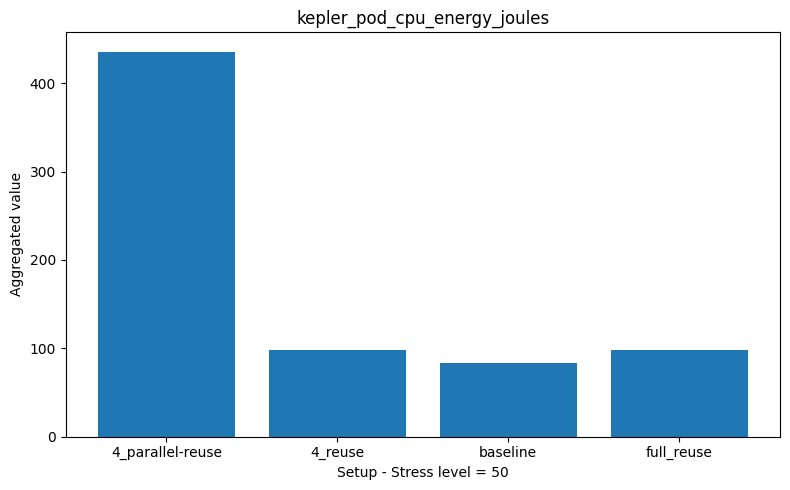

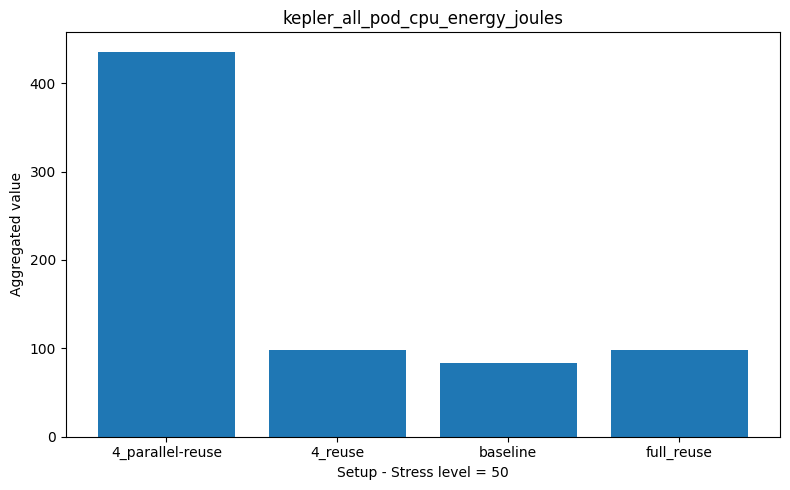

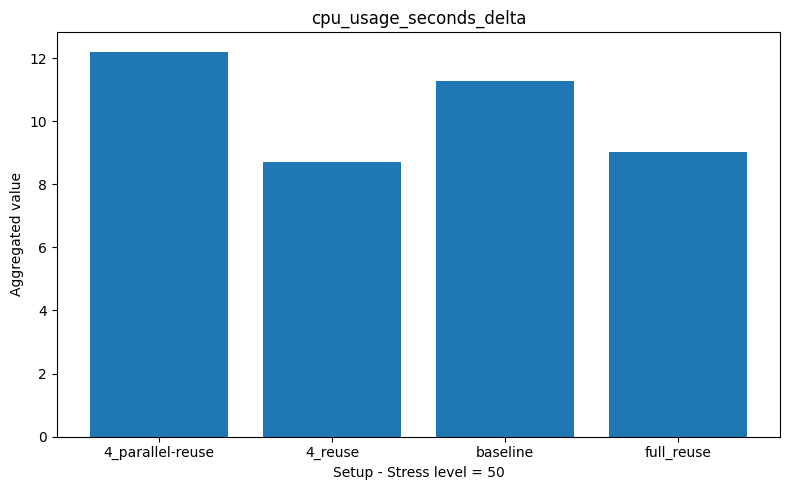

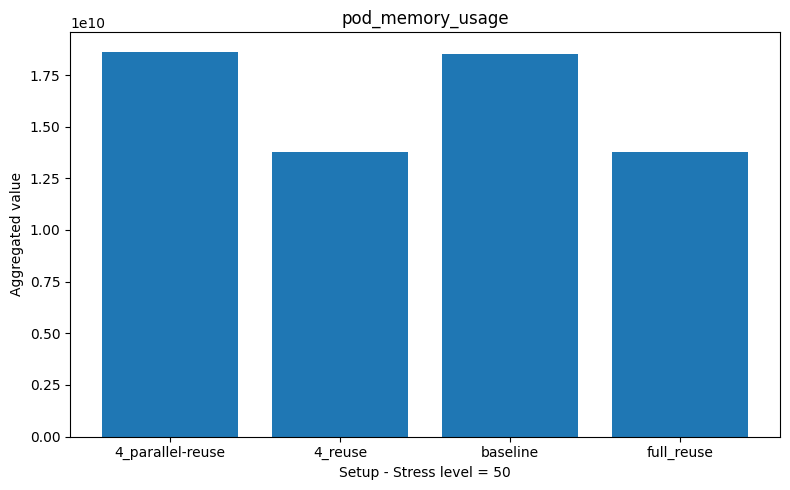

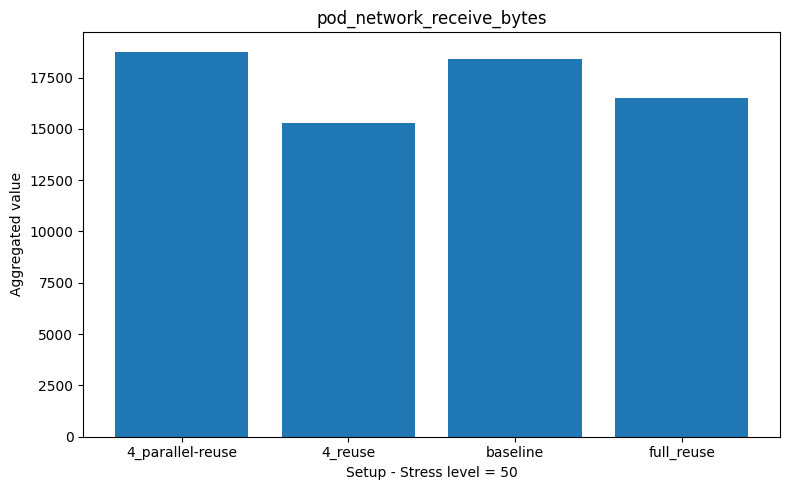

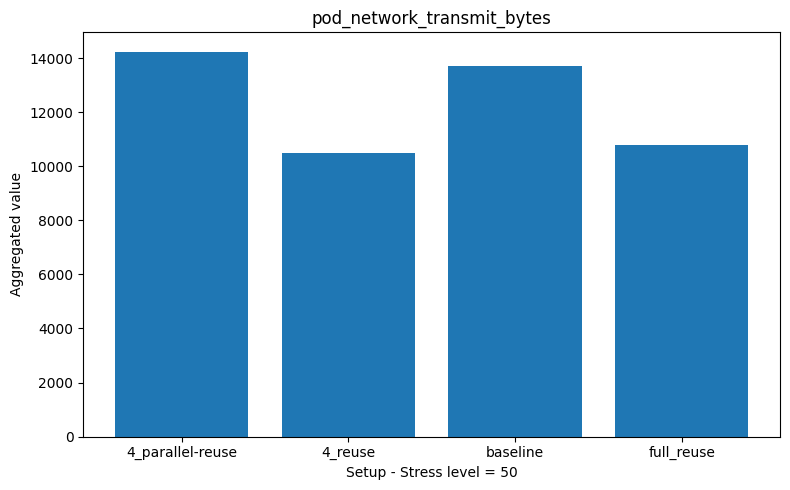

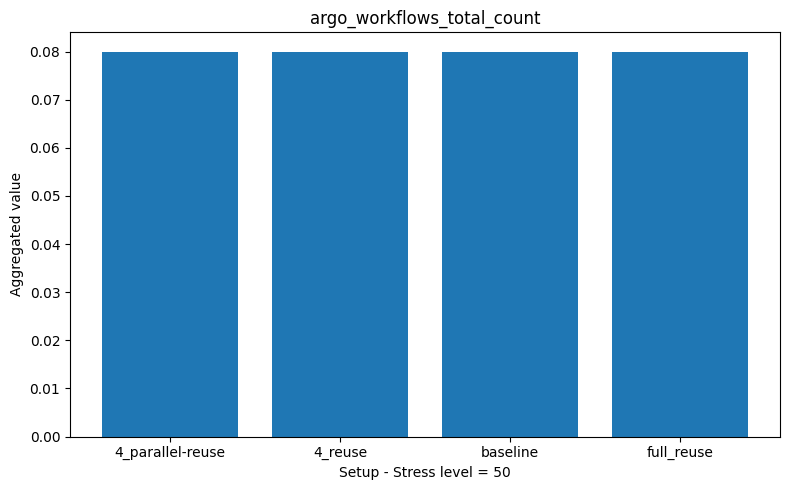

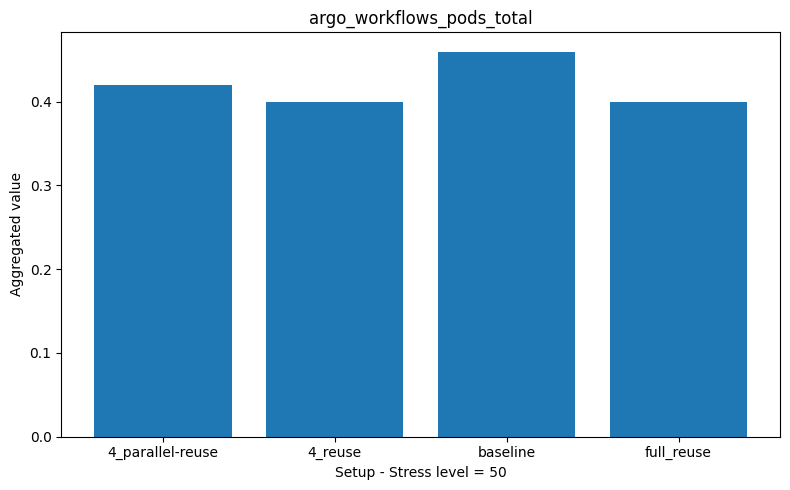

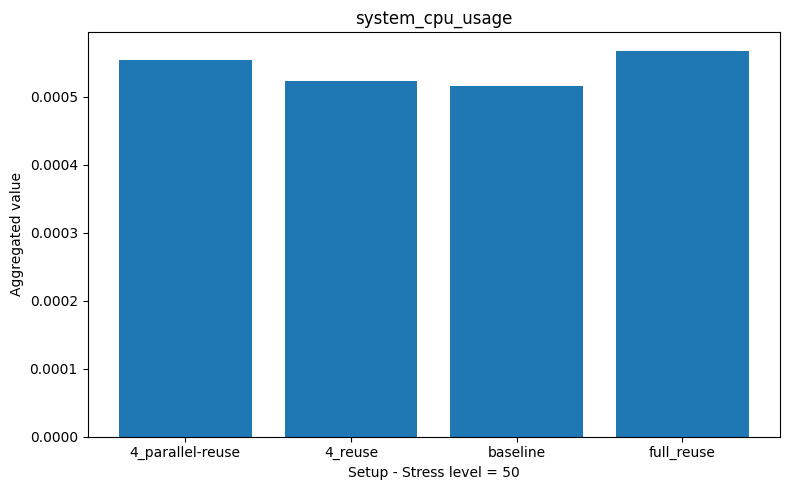

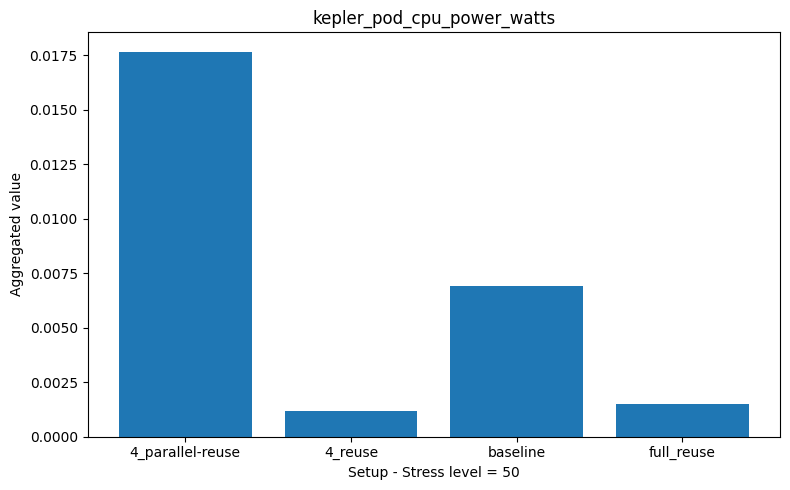

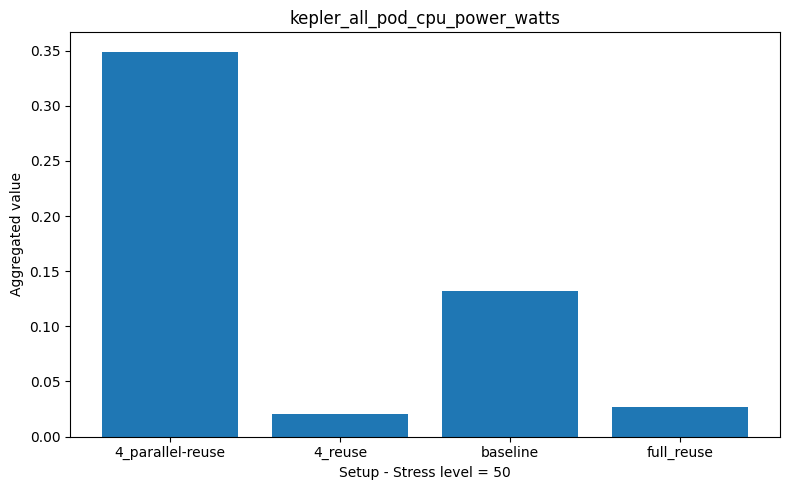

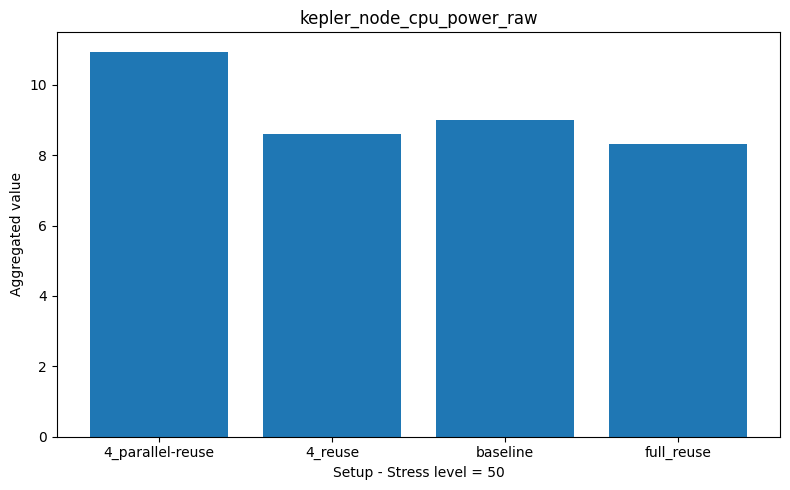

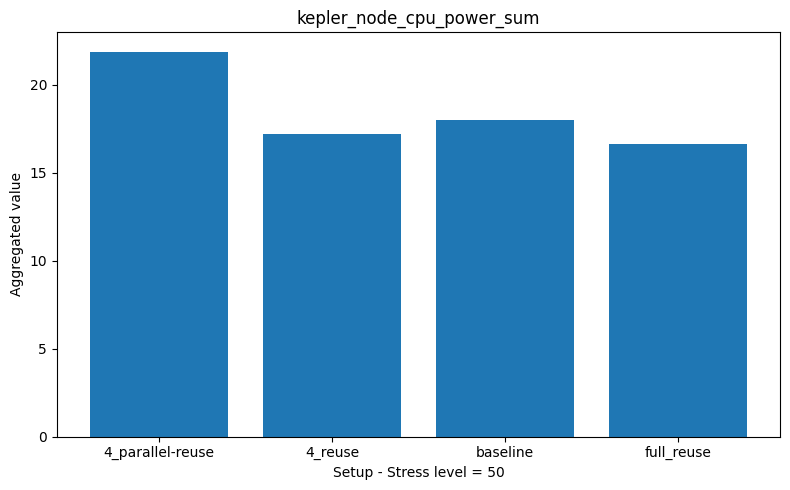

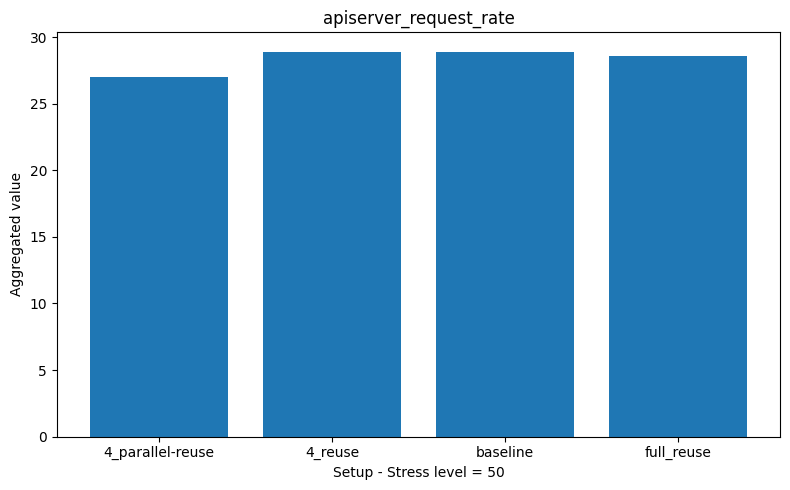

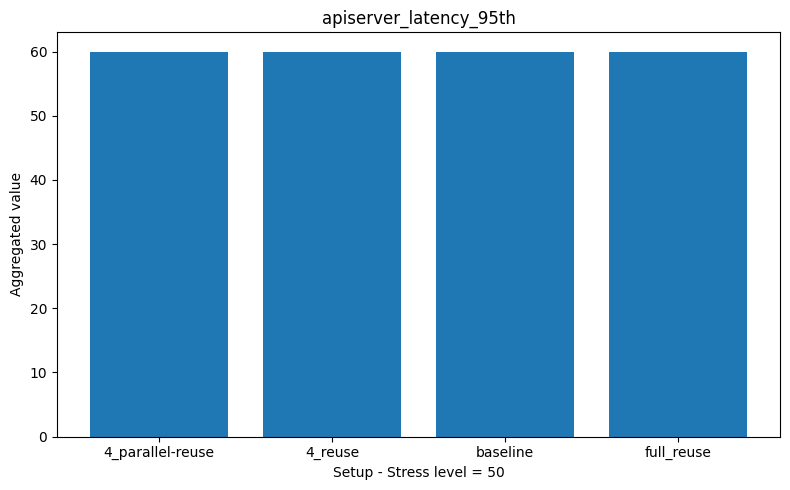

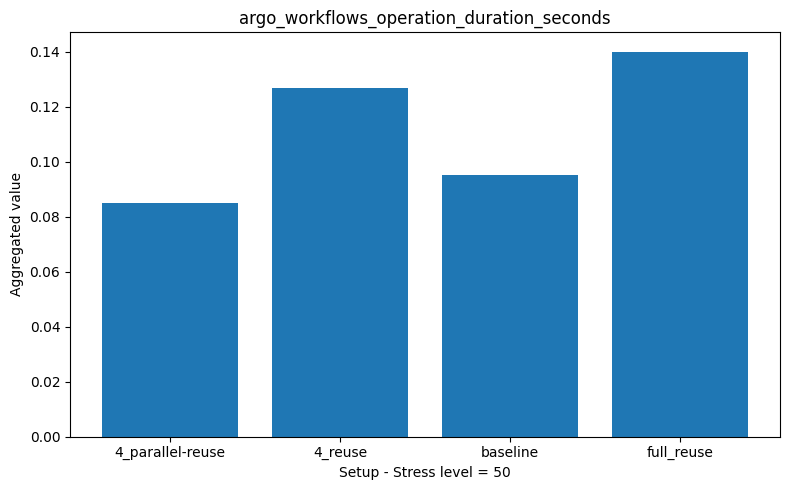

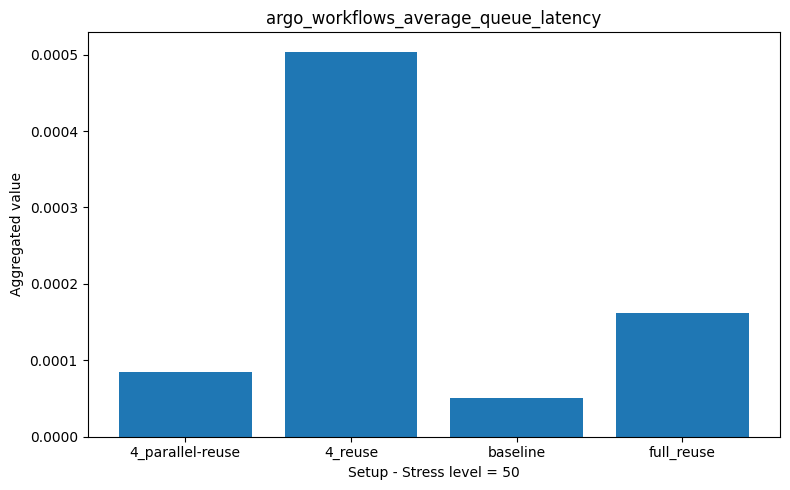

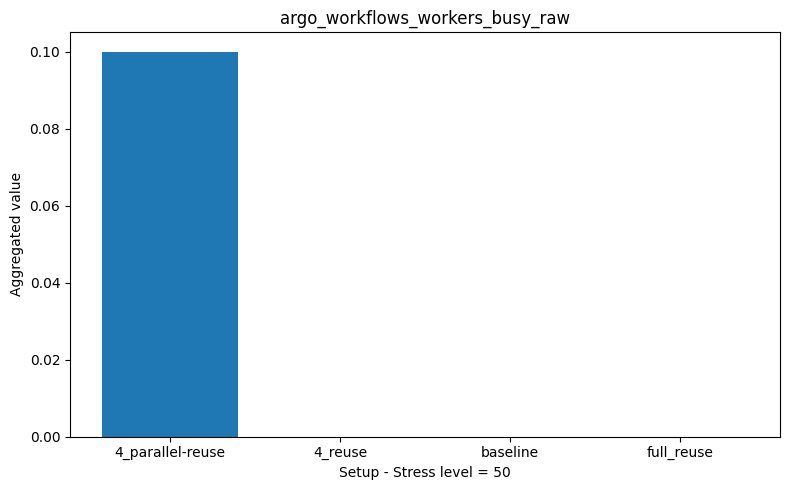

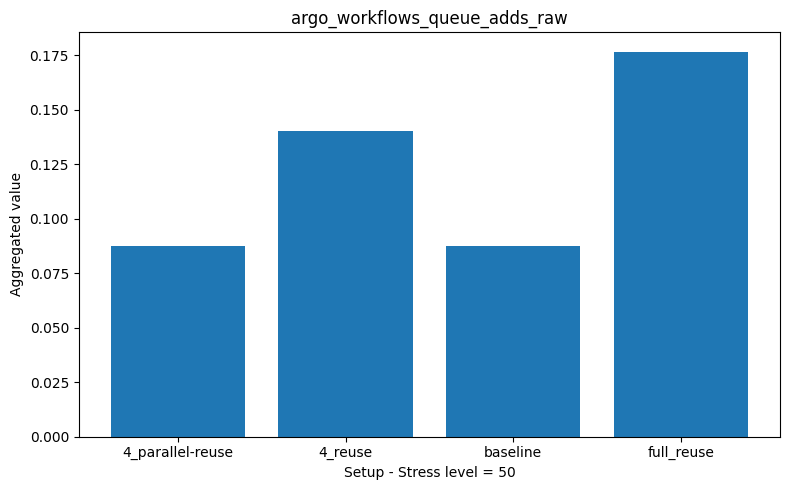

In [6]:
################# IMPACT OF NUMBER OF REUSED STEPS - STRESS=50 #################
#
#
# =========================================================
# Cell 1 – install required libraries (run first)
# =========================================================
!pip install pandas matplotlib numpy


# =========================================================
# Cell 2 – imports and global config
# =========================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)


# =========================================================
# Cell 3 – experiment structure
# =========================================================
SETUPS = {
    "4_parallel-reuse": "./step_reuse_1000_baremetal_2026_02_04_16_35_19_25ecc41f/data/", # 4_parallel-reuse
    "4_reuse": "./step_reuse_1000_baremetal_2026_02_04_16_39_46_58dc56eb/data/", # 4-reuse
    "baseline": "./step_reuse_1000_baremetal_2026_02_04_16_44_57_c7c83ff6/data/", # baseline
    "full_reuse": "./step_reuse_1000_baremetal_2026_02_04_16_49_09_a4d7701b/data/",  # full_reuse
} 

SUM_METRICS = [
    "kepler_pod_cpu_energy_joules",
    "kepler_all_pod_cpu_energy_joules",
    "cpu_usage_seconds_delta",
    "pod_memory_usage",
    "pod_network_receive_bytes",
    "pod_network_transmit_bytes",
    "argo_workflows_total_count",
    "argo_workflows_error_count",
    "argo_workflows_pods_total",
]

MEAN_METRICS = [
    "system_cpu_usage",
    "kepler_pod_cpu_power_watts",
    "kepler_all_pod_cpu_power_watts",
    "kepler_node_cpu_power_raw",
    "kepler_node_cpu_power_sum",
    "wall_power",
    "apiserver_request_rate",
    "apiserver_latency_95th",
    "argo_workflows_operation_duration_seconds",
    "argo_workflows_average_queue_latency",
    "argo_workflows_workers_busy_raw",
    "argo_workflows_queue_adds_raw",
    "argo_workflows_k8s_requests_raw",
]

ALL_METRICS = SUM_METRICS + MEAN_METRICS


# =========================================================
# Cell 4 – helper functions (CORRECT COLUMN HANDLING)
# =========================================================
def load_metric(csv_path, metric_name):
    df = pd.read_csv(csv_path)

    if metric_name not in df.columns:
        raise ValueError(
            f"Column '{metric_name}' not found in {csv_path}. "
            f"Available columns: {list(df.columns)}"
        )

    return df[metric_name]


def aggregate(series, metric_name):
    if metric_name in SUM_METRICS:
        return series.sum()
    return series.mean()


# =========================================================
# Cell 5 – load and aggregate values PER SETUP
# =========================================================
aggregated = {metric: {} for metric in ALL_METRICS}

for setup, base_path in SETUPS.items():
    for metric in ALL_METRICS:
        csv_file = os.path.join(base_path, f"{metric}.csv")

        if not os.path.exists(csv_file):
            continue

        values = load_metric(csv_file, metric)
        aggregated[metric][setup] = aggregate(values, metric)

results_df = pd.DataFrame(aggregated).T
results_df.to_csv("aggregated_metrics_comparison.csv")


# =========================================================
# Cell 6 – plotting (one plot per metric)
# =========================================================
for metric in results_df.index:
    data = results_df.loc[metric].dropna()

    if data.empty:
        continue

    plt.figure()
    plt.bar(data.index, data.values)
    plt.title(metric)
    plt.xlabel("Setup - Stress level = 50")
    plt.ylabel("Aggregated value")
    plt.tight_layout()
    plt.show()


[notice] A new release of pip available: 22.2.2 -> 26.0
[notice] To update, run: pip install --upgrade pip


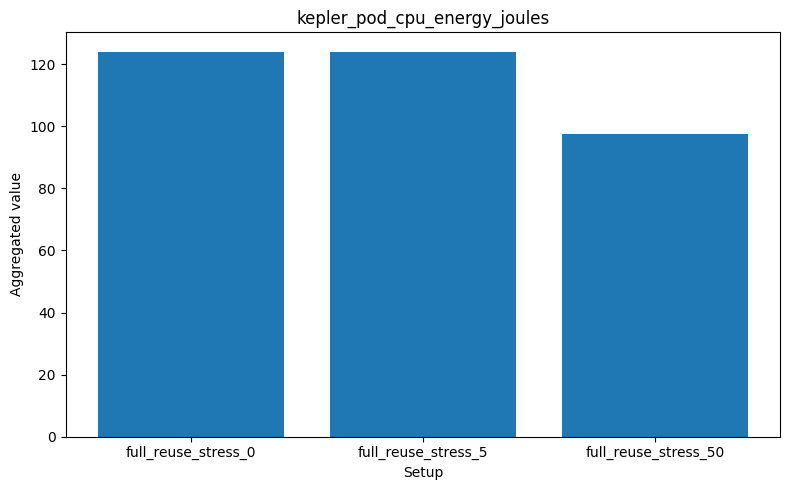

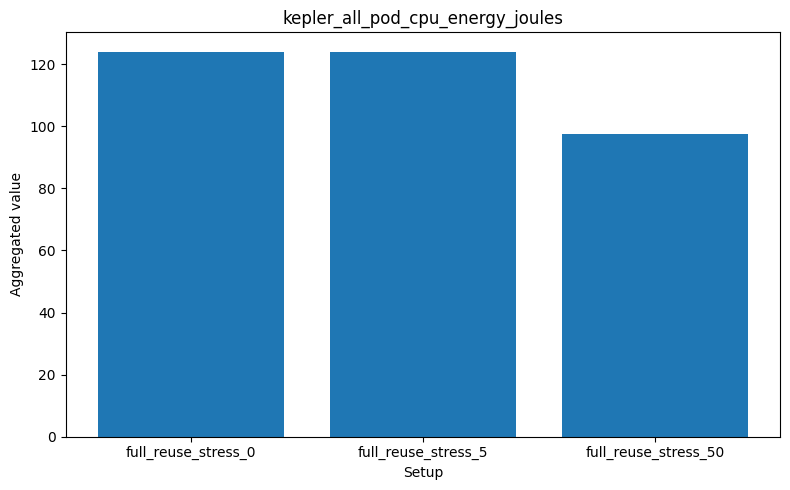

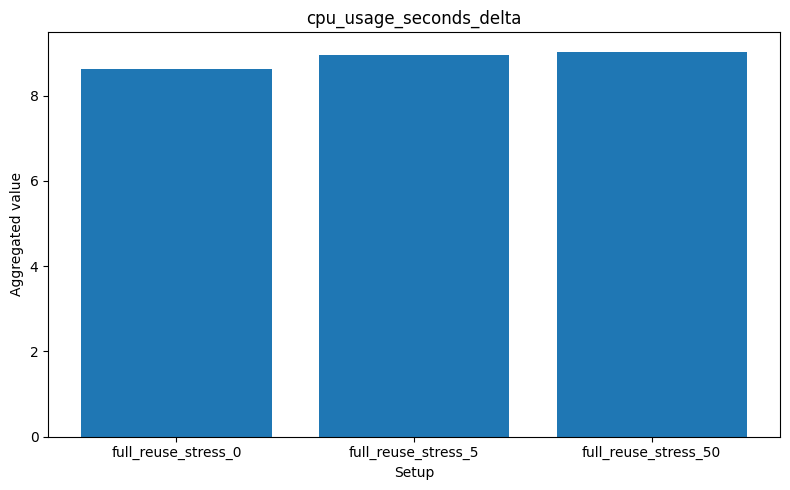

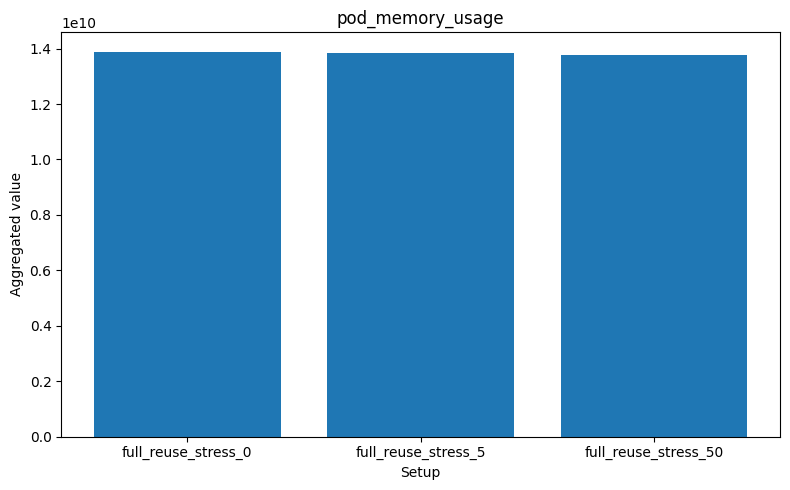

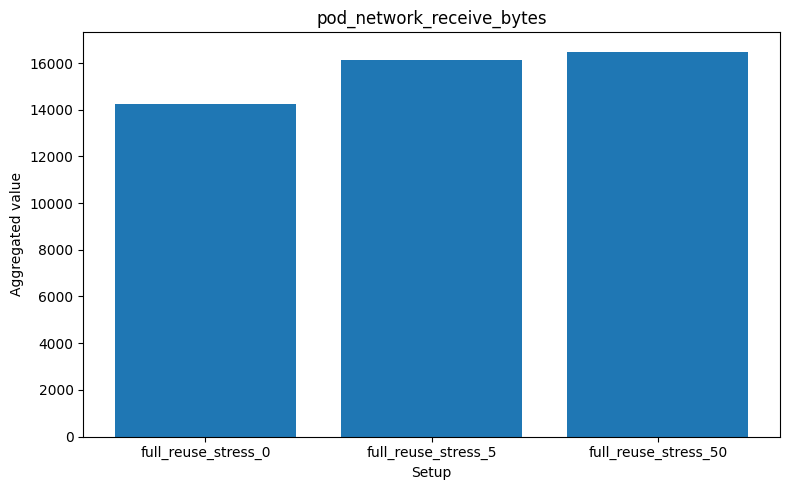

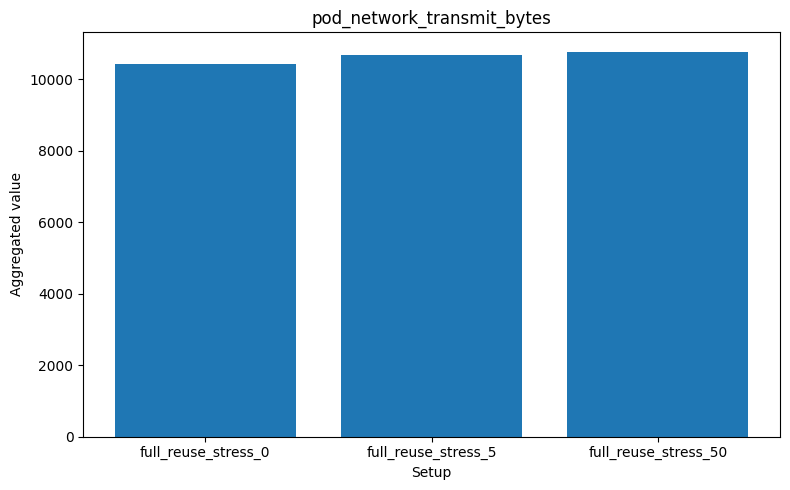

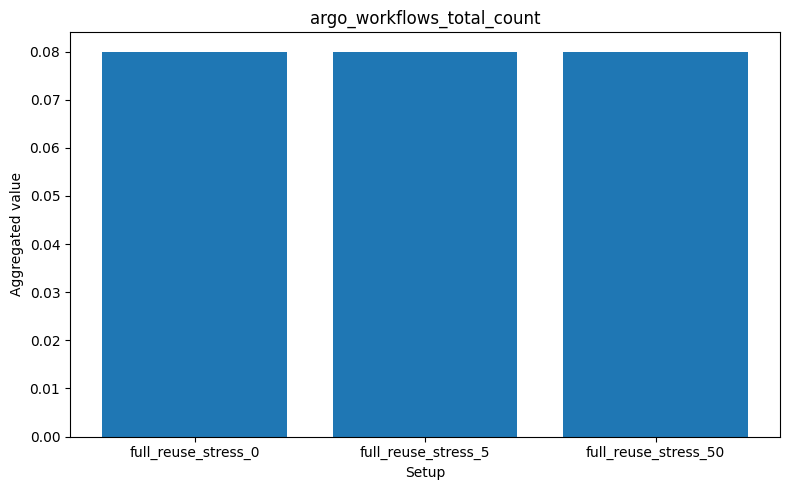

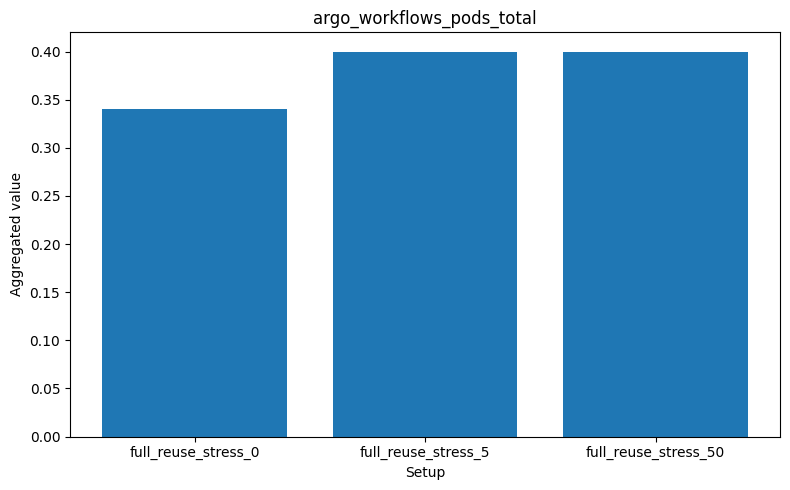

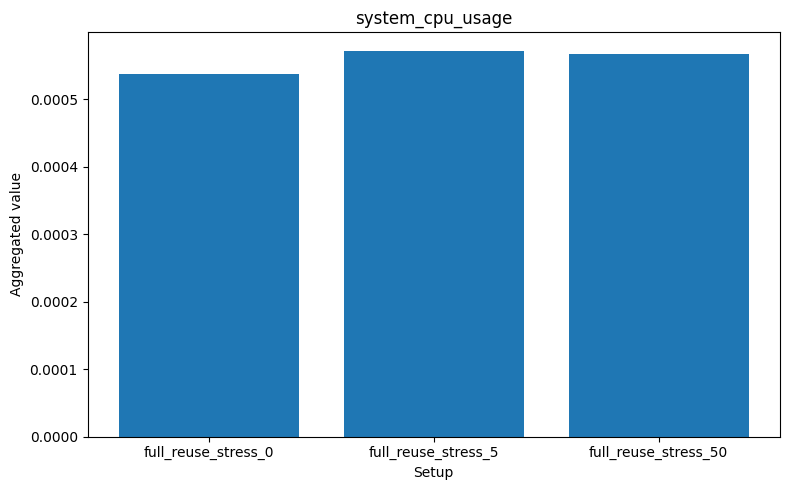

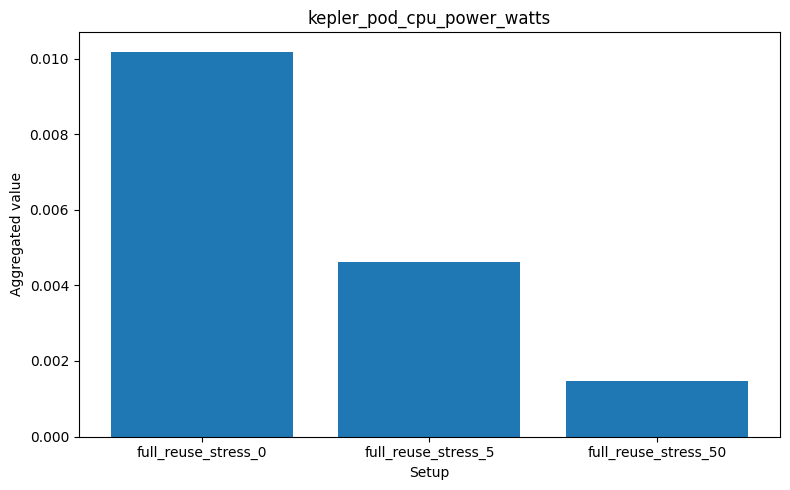

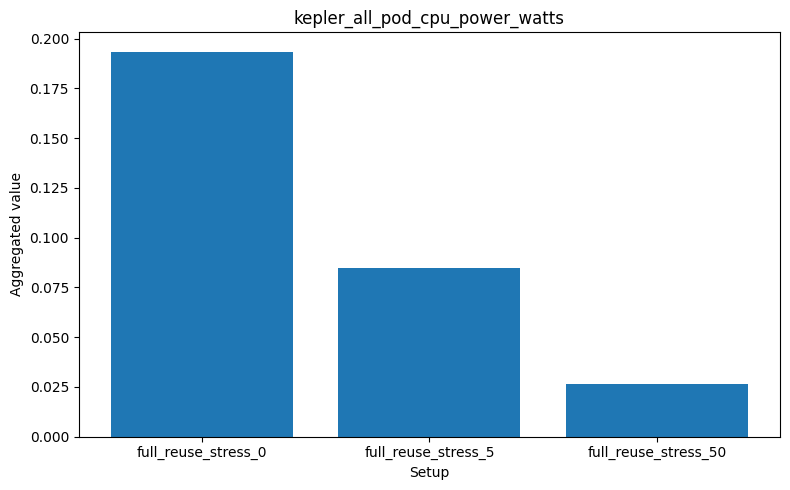

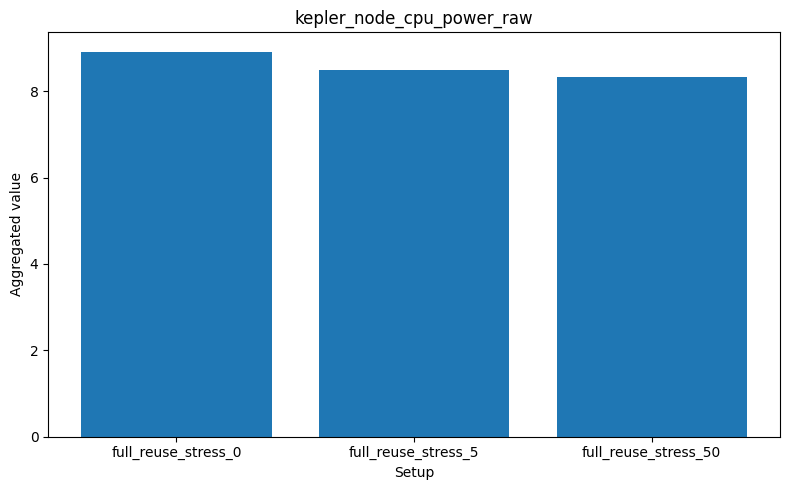

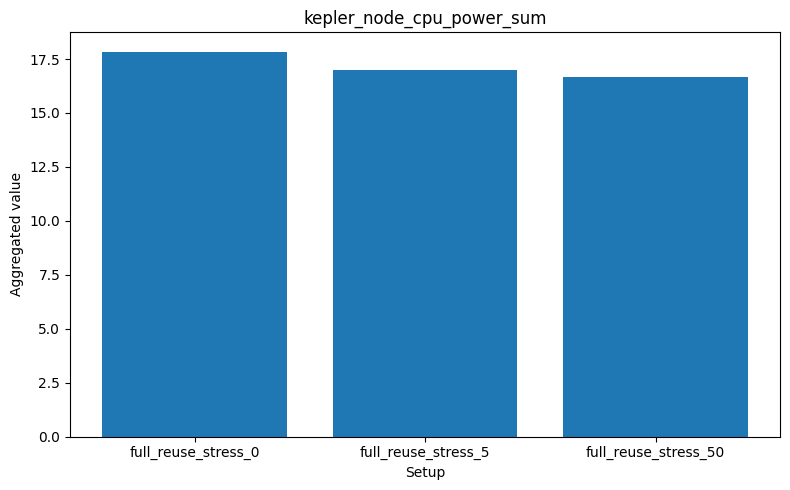

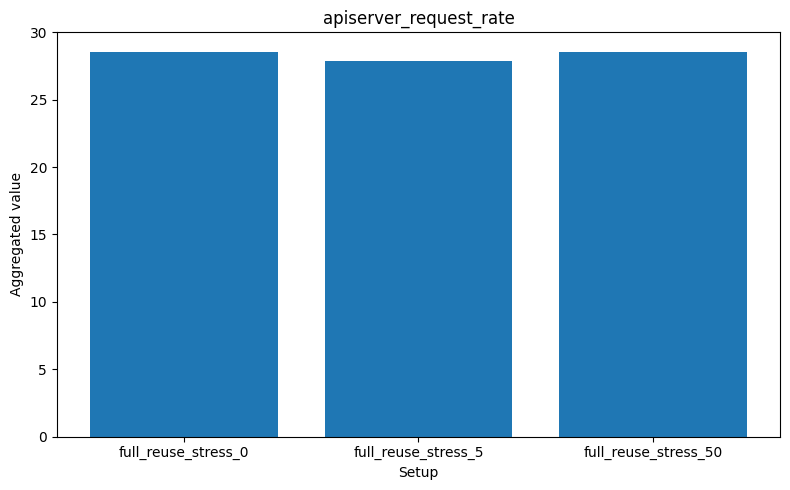

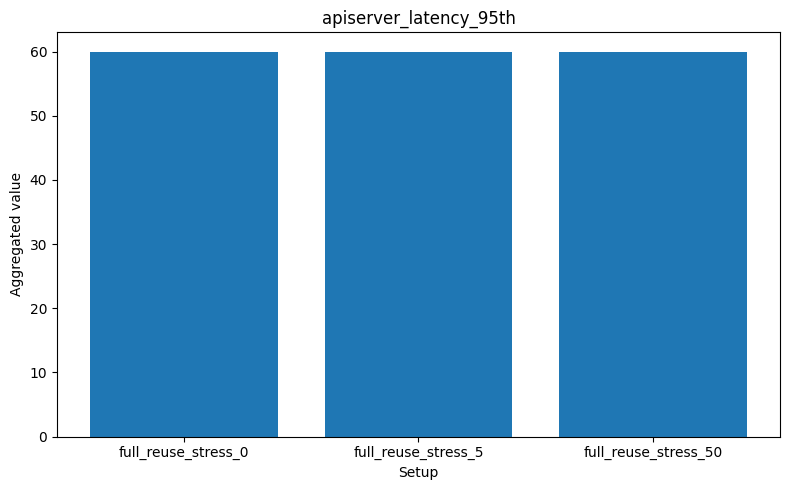

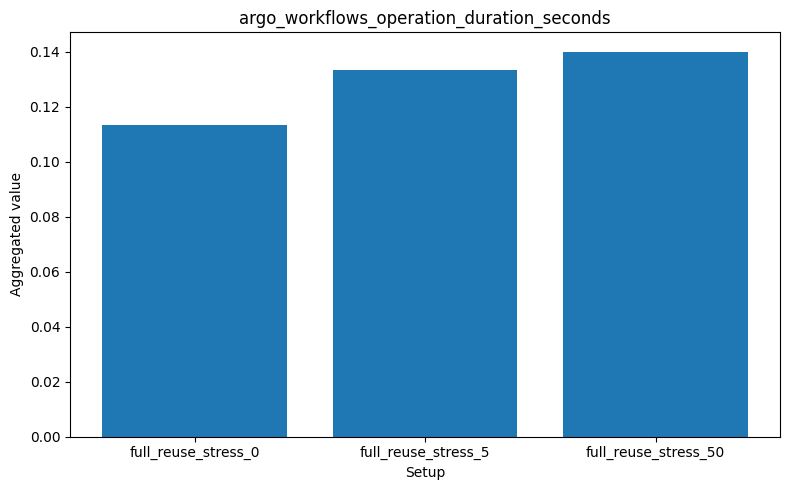

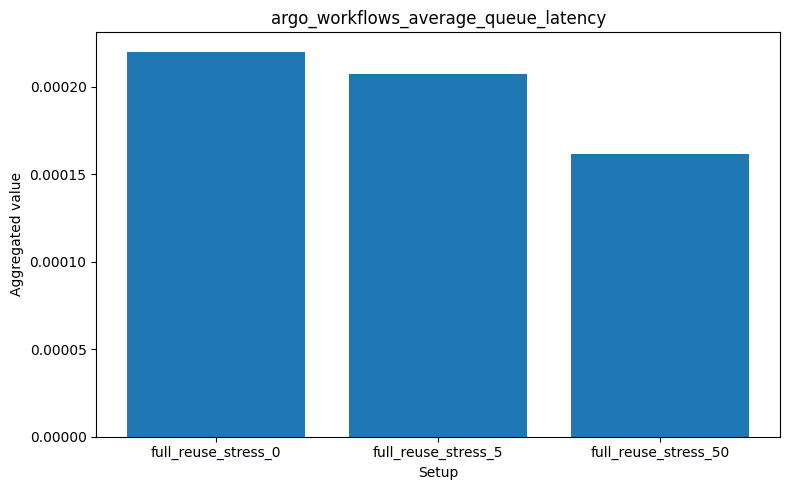

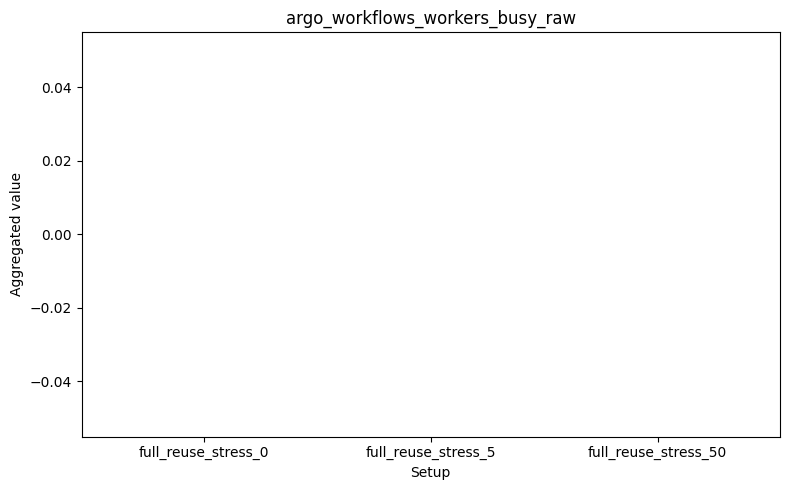

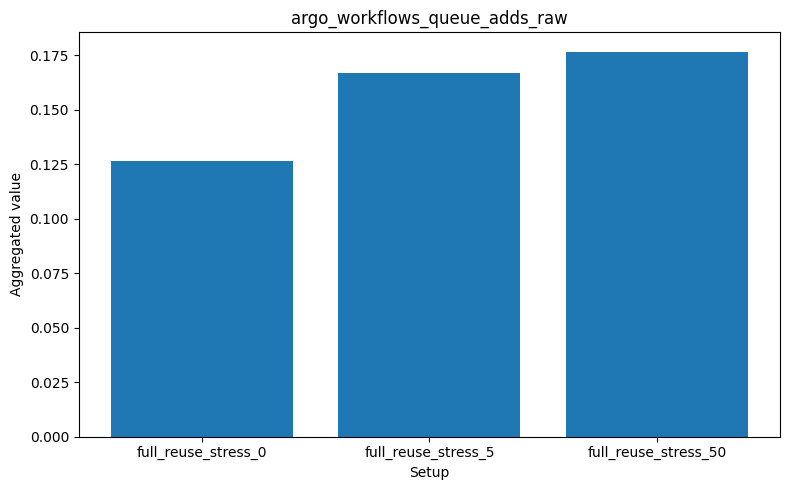

In [5]:
################# IMPACT OF STRESS = 0 , FULL_REUSE #################
#
#
# =========================================================
# Cell 1 – install required libraries (run first)
# =========================================================
!pip install pandas matplotlib numpy


# =========================================================
# Cell 2 – imports and global config
# =========================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)


# =========================================================
# Cell 3 – experiment structure
# =========================================================
SETUPS = {
    "full_reuse_stress_0": "./step_reuse_1000_baremetal_2026_02_04_16_46_47_dc9db2e2/data/",
    "full_reuse_stress_5": "./step_reuse_1000_baremetal_2026_02_04_16_47_58_3604741e/data/",
    "full_reuse_stress_50": "./step_reuse_1000_baremetal_2026_02_04_16_49_09_a4d7701b/data/"
}

SUM_METRICS = [
    "kepler_pod_cpu_energy_joules",
    "kepler_all_pod_cpu_energy_joules",
    "cpu_usage_seconds_delta",
    "pod_memory_usage",
    "pod_network_receive_bytes",
    "pod_network_transmit_bytes",
    "argo_workflows_total_count",
    "argo_workflows_error_count",
    "argo_workflows_pods_total",
]

MEAN_METRICS = [
    "system_cpu_usage",
    "kepler_pod_cpu_power_watts",
    "kepler_all_pod_cpu_power_watts",
    "kepler_node_cpu_power_raw",
    "kepler_node_cpu_power_sum",
    "wall_power",
    "apiserver_request_rate",
    "apiserver_latency_95th",
    "argo_workflows_operation_duration_seconds",
    "argo_workflows_average_queue_latency",
    "argo_workflows_workers_busy_raw",
    "argo_workflows_queue_adds_raw",
    "argo_workflows_k8s_requests_raw",
]

ALL_METRICS = SUM_METRICS + MEAN_METRICS


# =========================================================
# Cell 4 – helper functions (CORRECT COLUMN HANDLING)
# =========================================================
def load_metric(csv_path, metric_name):
    df = pd.read_csv(csv_path)

    if metric_name not in df.columns:
        raise ValueError(
            f"Column '{metric_name}' not found in {csv_path}. "
            f"Available columns: {list(df.columns)}"
        )

    return df[metric_name]


def aggregate(series, metric_name):
    if metric_name in SUM_METRICS:
        return series.sum()
    return series.mean()


# =========================================================
# Cell 5 – load and aggregate values PER SETUP
# =========================================================
aggregated = {metric: {} for metric in ALL_METRICS}

for setup, base_path in SETUPS.items():
    for metric in ALL_METRICS:
        csv_file = os.path.join(base_path, f"{metric}.csv")

        if not os.path.exists(csv_file):
            continue

        values = load_metric(csv_file, metric)
        aggregated[metric][setup] = aggregate(values, metric)

results_df = pd.DataFrame(aggregated).T
results_df.to_csv("aggregated_metrics_comparison.csv")


# =========================================================
# Cell 6 – plotting (one plot per metric)
# =========================================================
for metric in results_df.index:
    data = results_df.loc[metric].dropna()

    if data.empty:
        continue

    plt.figure()
    plt.bar(data.index, data.values)
    plt.title(metric)
    plt.xlabel("Setup")
    plt.ylabel("Aggregated value")
    plt.tight_layout()
    plt.show()


[notice] A new release of pip available: 22.2.2 -> 26.0
[notice] To update, run: pip install --upgrade pip
Metric: kepler_pod_cpu_energy_joules, Reuse: no-reuse
  Stress 0: 35.87878255172413
  Stress 5: 27.17634413793105
  Stress 50: 82.7580214482759
Metric: kepler_pod_cpu_energy_joules, Reuse: 4-reuse
  Stress 0: 285.71970626834485
  Stress 5: 200.24388175862074
  Stress 50: 97.5058542935586
Metric: kepler_pod_cpu_energy_joules, Reuse: 4-parallel-reuse
  Stress 0: 95.30101012068963
  Stress 5: 228.30650979310343
  Stress 50: 435.97414034482756
Metric: kepler_pod_cpu_energy_joules, Reuse: full-reuse
  Stress 0: 124.1204045172414
  Stress 5: 124.13152313793107
  Stress 50: 97.67977793103448
Metric: kepler_all_pod_cpu_energy_joules, Reuse: no-reuse
  Stress 0: 35.87878255172413
  Stress 5: 27.176344137931054
  Stress 50: 82.75802144827591
Metric: kepler_all_pod_cpu_energy_joules, Reuse: 4-reuse
  Stress 0: 285.7197062683448
  Stress 5: 200.24388175862072
  Stress 50: 97.50585429355863
M

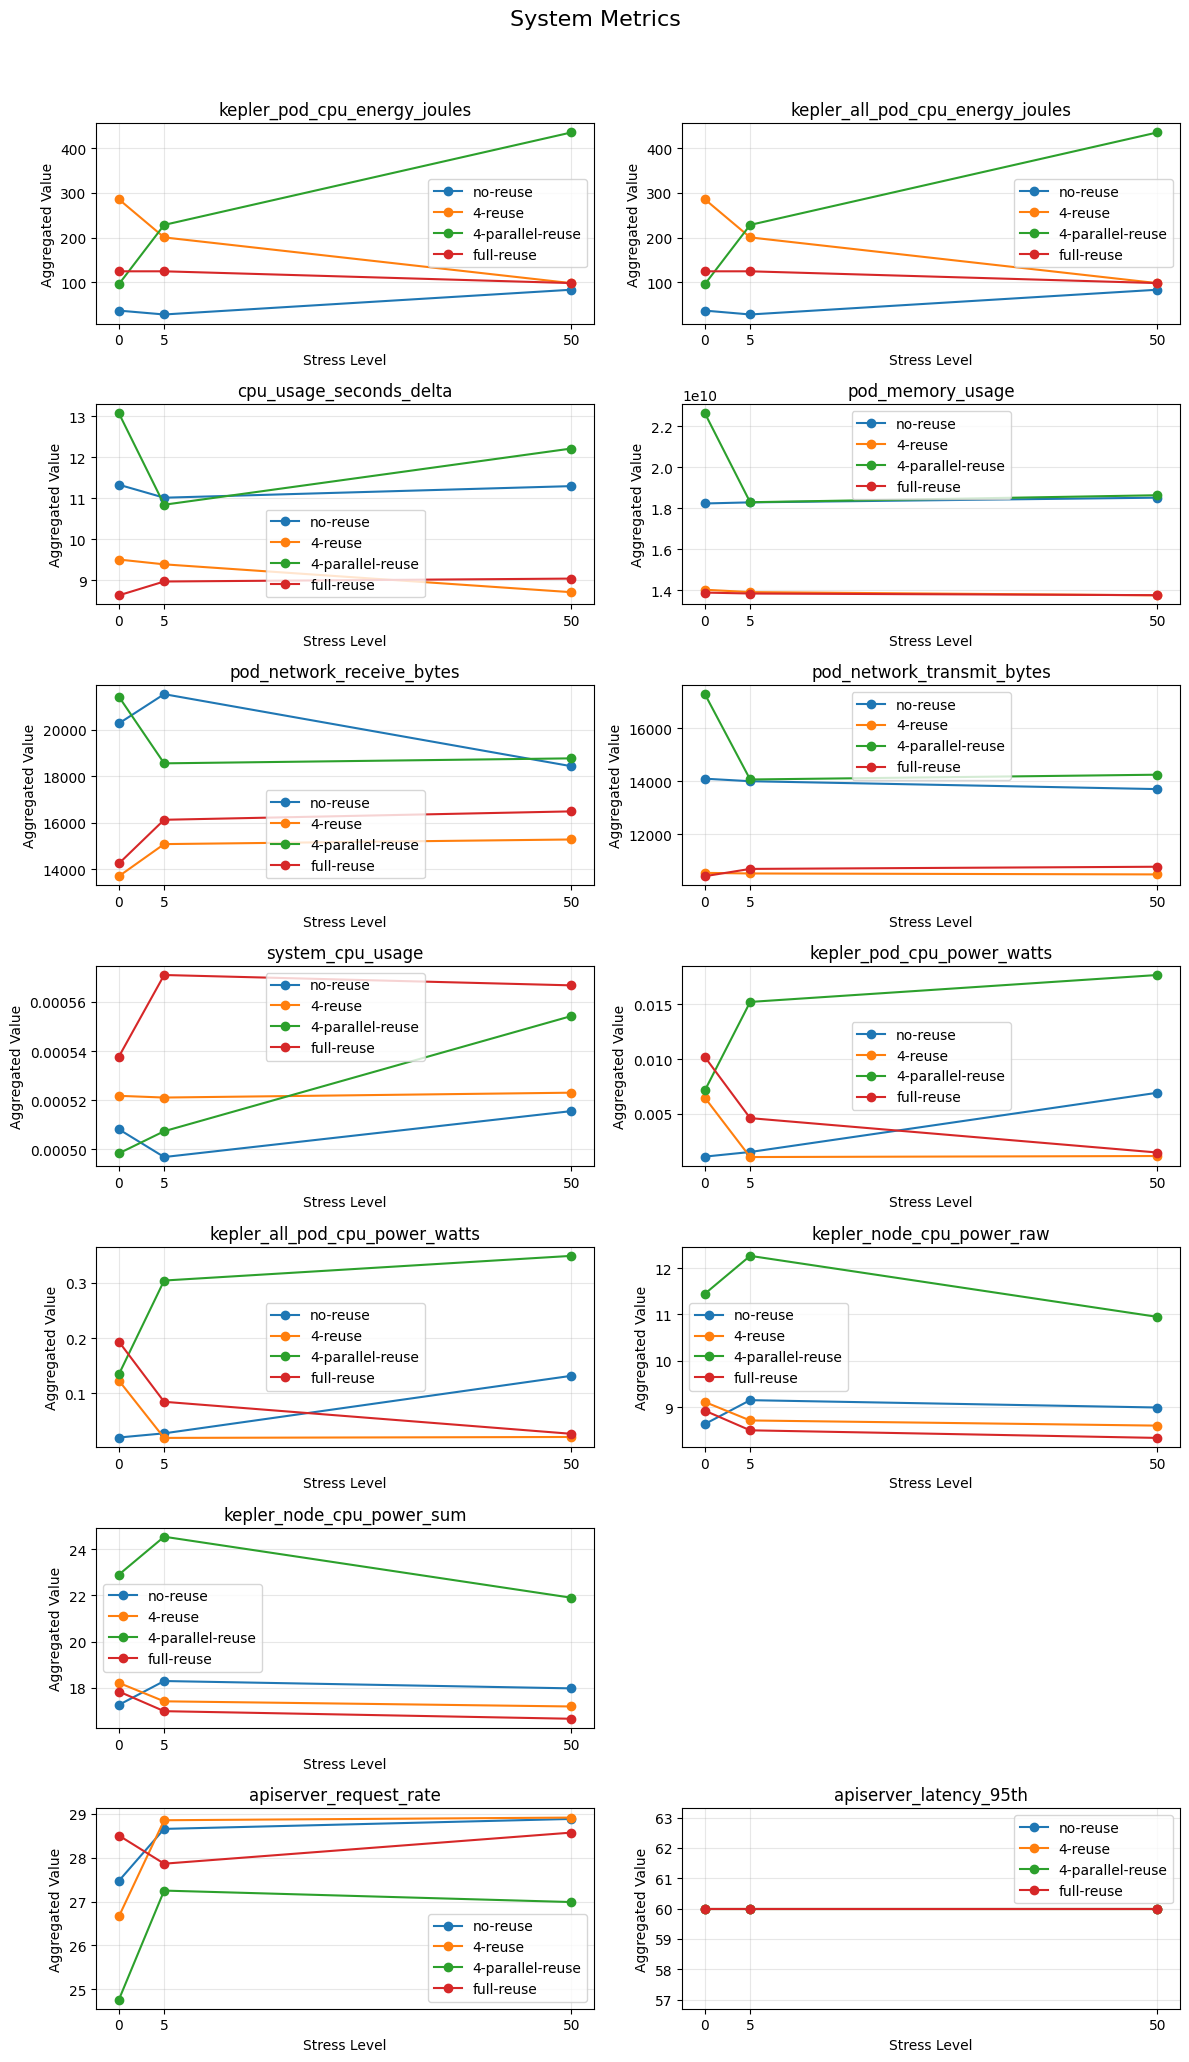

Metric: kepler_pod_cpu_energy_joules, Reuse: no-reuse
  Stress 0: 35.87878255172413
  Stress 5: 27.17634413793105
  Stress 50: 82.7580214482759
Metric: kepler_pod_cpu_energy_joules, Reuse: 4-reuse
  Stress 0: 285.71970626834485
  Stress 5: 200.24388175862074
  Stress 50: 97.5058542935586
Metric: kepler_pod_cpu_energy_joules, Reuse: 4-parallel-reuse
  Stress 0: 95.30101012068963
  Stress 5: 228.30650979310343
  Stress 50: 435.97414034482756
Metric: kepler_pod_cpu_energy_joules, Reuse: full-reuse
  Stress 0: 124.1204045172414
  Stress 5: 124.13152313793107
  Stress 50: 97.67977793103448
Metric: kepler_all_pod_cpu_energy_joules, Reuse: no-reuse
  Stress 0: 35.87878255172413
  Stress 5: 27.176344137931054
  Stress 50: 82.75802144827591
Metric: kepler_all_pod_cpu_energy_joules, Reuse: 4-reuse
  Stress 0: 285.7197062683448
  Stress 5: 200.24388175862072
  Stress 50: 97.50585429355863
Metric: kepler_all_pod_cpu_energy_joules, Reuse: 4-parallel-reuse
  Stress 0: 95.30101012068964
  Stress 5: 2

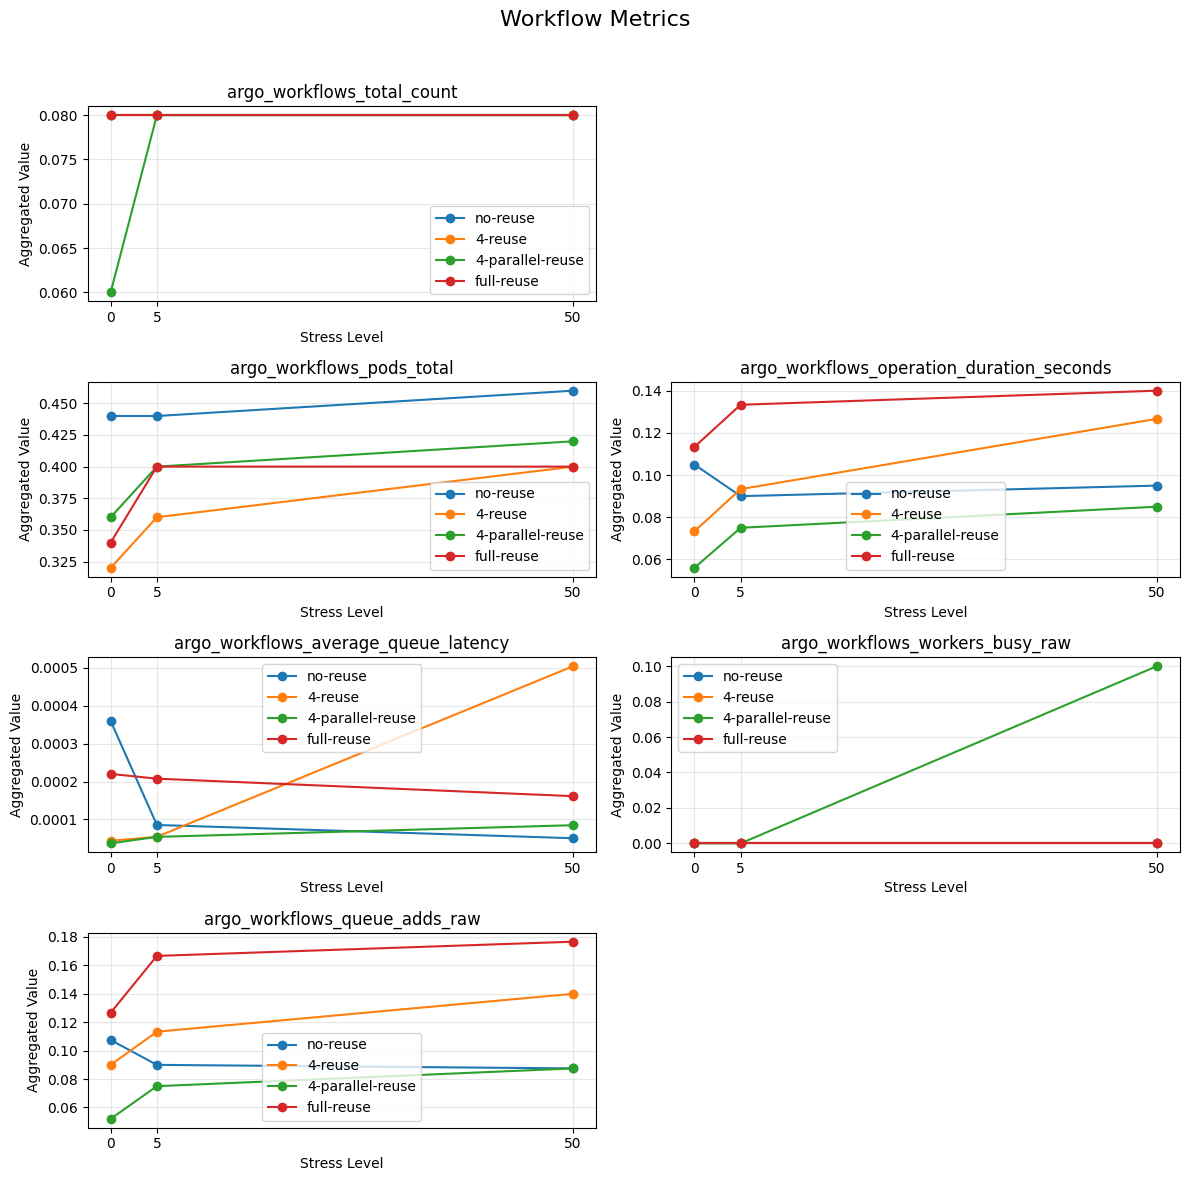

In [9]:
# =========================================================
# Cell 1 – install libraries
# =========================================================
!pip install pandas matplotlib numpy


# =========================================================
# Cell 2 – imports
# =========================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 6)


# =========================================================
# Cell 3 – define reuse types and manual folder mapping
# =========================================================
REUSE_TYPES = ["no-reuse", "4-reuse", "4-parallel-reuse", "full-reuse"]

# Manual folder mapping: path -> (reuse_type, stress_level)
FOLDER_MAPPING = {
    "./step_reuse_1000_baremetal_2026_02_04_16_31_18_8952049d/data/": ("4-parallel-reuse", 0),
    "./step_reuse_1000_baremetal_2026_02_04_16_33_20_1ed729ad/data/": ("4-parallel-reuse", 5),
    "./step_reuse_1000_baremetal_2026_02_04_16_35_19_25ecc41f/data/": ("4-parallel-reuse", 50),

    "./step_reuse_1000_baremetal_2026_02_04_16_37_15_855de02e/data/": ("4-reuse", 0),
    "./step_reuse_1000_baremetal_2026_02_04_16_38_36_defe5c6d/data/": ("4-reuse", 5),
    "./step_reuse_1000_baremetal_2026_02_04_16_39_46_58dc56eb/data/": ("4-reuse", 50),

    "./step_reuse_1000_baremetal_2026_02_04_16_41_07_4b4bba30/data/": ("no-reuse", 0),
    "./step_reuse_1000_baremetal_2026_02_04_16_43_04_f32295fc/data/": ("no-reuse", 5),
    "./step_reuse_1000_baremetal_2026_02_04_16_44_57_c7c83ff6/data/": ("no-reuse", 50),

    "./step_reuse_1000_baremetal_2026_02_04_16_46_47_dc9db2e2/data/": ("full-reuse", 0),
    "./step_reuse_1000_baremetal_2026_02_04_16_47_58_3604741e/data/": ("full-reuse", 5),
    "./step_reuse_1000_baremetal_2026_02_04_16_49_09_a4d7701b/data/": ("full-reuse", 50),
}



# =========================================================
# Cell 4 – define metrics
# =========================================================
SUM_METRICS = [
    "kepler_pod_cpu_energy_joules",
    "kepler_all_pod_cpu_energy_joules",
    "cpu_usage_seconds_delta",
    "pod_memory_usage",
    "pod_network_receive_bytes",
    "pod_network_transmit_bytes",
    "argo_workflows_total_count",
    "argo_workflows_error_count",
    "argo_workflows_pods_total",
]

MEAN_METRICS = [
    "system_cpu_usage",
    "kepler_pod_cpu_power_watts",
    "kepler_all_pod_cpu_power_watts",
    "kepler_node_cpu_power_raw",
    "kepler_node_cpu_power_sum",
    "wall_power",
    "apiserver_request_rate",
    "apiserver_latency_95th",
    "argo_workflows_operation_duration_seconds",
    "argo_workflows_average_queue_latency",
    "argo_workflows_workers_busy_raw",
    "argo_workflows_queue_adds_raw",
    "argo_workflows_k8s_requests_raw",
]

ALL_METRICS = SUM_METRICS + MEAN_METRICS


# =========================================================
# Cell 5 – helper functions
# =========================================================
def load_metric(csv_path, metric_name):
    if not os.path.exists(csv_path):
        print(f"Warning: CSV {csv_path} not found.")
        return None
    df = pd.read_csv(csv_path)
    if metric_name not in df.columns:
        print(f"Warning: Column '{metric_name}' not found in {csv_path}")
        return None
    return df[metric_name]

def aggregate(series, metric_name):
    if series is None or series.empty:
        return None
    if metric_name in SUM_METRICS:
        return series.sum()
    else:
        return series.mean()


# =========================================================
# Cell 6 – load and aggregate data robustly
# =========================================================
# Structure: data[metric][reuse_type][stress_level] = value
data = {metric: {reuse: {} for reuse in REUSE_TYPES} for metric in ALL_METRICS}

for folder, (reuse_type, stress_level) in FOLDER_MAPPING.items():
    if not os.path.exists(folder):
        print(f"Warning: Folder {folder} does not exist.")
        continue

    for metric in ALL_METRICS:
        csv_file = os.path.join(folder, f"{metric}.csv")
        series = load_metric(csv_file, metric)
        value = aggregate(series, metric)
        if value is not None:
            data[metric][reuse_type][stress_level] = value


# =========================================================
# Cell 7 – plotting metrics vs stress (multi-panel, robust, correct stress ticks)
# =========================================================
# Grouping system metrics vs workflow metrics
SYSTEM_METRICS = [m for m in ALL_METRICS if "argo" not in m]
WORKFLOW_METRICS = [m for m in ALL_METRICS if "argo" in m]

STRESS_LEVELS = [0, 5, 50]  # force correct X-axis ticks

def plot_metric_group(metric_list, group_name):
    
    for metric in ALL_METRICS:
        for reuse in REUSE_TYPES:
            print(f"Metric: {metric}, Reuse: {reuse}")
            for folder, (r, stress) in FOLDER_MAPPING.items():
                if r != reuse:
                    continue
                csv_file = os.path.join(folder, f"{metric}.csv")
                series = load_metric(csv_file, metric)
                if series is not None:
                    print(f"  Stress {stress}: {series.sum() if metric in SUM_METRICS else series.mean()}")
    
    n = len(metric_list)
    cols = 2
    rows = (n + 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(12, rows*3))
    axes = axes.flatten()

    for idx, metric in enumerate(metric_list):
        ax = axes[idx]
        has_data = False
        for reuse in REUSE_TYPES:
            reuse_data = data[metric][reuse]
            if not reuse_data:
                continue
            # Only use stress levels available for this reuse type
            x = [s for s in STRESS_LEVELS if s in reuse_data]
            y = [reuse_data[s] for s in x]
            ax.plot(x, y, marker='o', linestyle='-', label=reuse)
            has_data = True
        if not has_data:
            ax.set_visible(False)
            continue
        ax.set_title(metric)
        ax.set_xlabel("Stress Level")
        ax.set_ylabel("Aggregated Value")
        ax.set_xticks(STRESS_LEVELS)   # force exact stress ticks
        ax.grid(alpha=0.3)
        ax.legend()
    # Hide empty subplots
    for j in range(idx+1, len(axes)):
        axes[j].set_visible(False)
    fig.suptitle(group_name, fontsize=16)
    plt.tight_layout(rect=[0,0,1,0.96])
    plt.show()
    plt.close(fig)

# Plot system metrics
plot_metric_group(SYSTEM_METRICS, "System Metrics")

# Plot workflow/argo metrics
plot_metric_group(WORKFLOW_METRICS, "Workflow Metrics")

